# ZeroSyl syllable-boundary evaluation

This notebook scores a ZeroSyl-estimated Praat `TextGrid` against a manually
annotated ground-truth `TextGrid` for a single recording.

**What it does differently from `zerosyl_boundary_performance_evaluation.ipynb`:**

1. **Input format.** `boundaries.py` was written to evaluate a whole dev-set
   of `.pt` segment tensors against a folder of `TextGrid`s
   (`evaluate_boundary_metrics(segments_dir, textgrid_dir, ...)`). That format is
   **not** used here. Instead this notebook takes exactly three files directly:
   a ground-truth `TextGrid`, an estimated `TextGrid`, and the `.wav` they were
   both derived from.
2. **Metrics.** Only the metrics `boundaries.py` itself computes are reported:
   boundary precision / recall / F1, over-segmentation (OS), R-value, and the
   token-level precision / recall / F1. The one-to-one DP matcher, tolerance
   sweep, and CSV export in the old notebook are dropped — they are not part
   of `boundaries.py`'s methodology and are not needed here.
3. **Matching logic.** The functions below (`split_utterance`, `get_p_r_f1`,
   `eval_boundaries`, `get_os`, `get_rvalue`, `eval_token_boundaries`) are
   copied **verbatim** from `boundaries.py`. The only thing that changed is
   *how the estimated boundary list is produced* (read from a `TextGrid` tier
   instead of a `.pt` segment tensor) — the scoring logic itself is untouched.
4. **Visualization.** Section 5 reuses the full-recording plot style from the
   old notebook (blue ground-truth lines, green TP circles, red FP crosses,
   orange FN triangles). Section 6 is a new tool: an interactive, scrollable
   viewer that lines up the boundary evaluation, both `TextGrid` tiers, and
   the waveform in one synchronized view so the three can be compared directly.

## 1. Configuration

In [12]:
from pathlib import Path

# GROUND_TRUTH_TEXTGRID = Path("HendrikEng10SecSilence.TextGrid")
# ESTIMATED_TEXTGRID = Path("ZeroSyl_HendrikEng10Sec_syllables.TextGrid")
# AUDIO_WAV = Path("HendrikEng10Sec.flac")

#GROUND_TRUTH_TEXTGRID = Path("HendrikEng10Sec.TextGrid")#This one is bad
GROUND_TRUTH_TEXTGRID = Path("HendrikEng10SecSilence.TextGrid")#this one good
ESTIMATED_TEXTGRID = Path("ZeroSyl_HendrikEng10Sec_syllables.TextGrid")
AUDIO_WAV = Path("HendrikEng10Sec.flac")

GROUND_TRUTH_TIER = "syllables"
ESTIMATED_TIER = "syllables"

TOLERANCE_S = 0.05  # 50 ms, same default as boundaries.py

print("Ground truth TextGrid:", GROUND_TRUTH_TEXTGRID.resolve())
print("Estimated TextGrid:   ", ESTIMATED_TEXTGRID.resolve())
print("Audio:                ", AUDIO_WAV.resolve())
print(f"Tolerance:              ±{TOLERANCE_S * 1000:.0f} ms")

Ground truth TextGrid: /home/hendrik/Skripsie/JupyterNotebooks/HendrikEng10SecSilence.TextGrid
Estimated TextGrid:    /home/hendrik/Skripsie/JupyterNotebooks/ZeroSyl_HendrikEng10Sec_syllables.TextGrid
Audio:                 /home/hendrik/Skripsie/JupyterNotebooks/HendrikEng10Sec.flac
Tolerance:              ±50 ms


## 2. `boundaries.py` methodology (copied verbatim)

These are the exact functions from `boundaries.py`, minus the `.pt` / dev-set
loading front end (`evaluate_boundary_metrics`), which required `torch` and a
dataset laid out as `segments_dir` + `textgrid_dir`. The scoring functions
themselves have no dependency on that front end, so they are reproduced here
unmodified.

In [13]:
import itertools
from typing import List, Tuple

import jupyter_capture_output



import numpy as np
import tgt


def split_utterance(
    seg: List[float], ref: "tgt.IntervalTier", tolerance: float
) -> Tuple[List[List[float]], List[List[float]]]:
    """Verbatim from boundaries.py."""
    ref_out = [
        list(ref_utt)
        for k, ref_utt in itertools.groupby(ref.intervals, lambda x: x.text != "")
        if k
    ]

    seg_out = []
    for ref_utt in ref_out:
        ref_utt_onset = ref_utt[0].start_time + tolerance
        ref_utt_offset = ref_utt[-1].end_time - tolerance
        seg_out.append([s for s in seg if ref_utt_onset < s < ref_utt_offset])
        seg_out[-1].append(ref_utt[-1].end_time)

    return seg_out, [
        [float(interval.end_time) for interval in ref_utt] for ref_utt in ref_out
    ]


def get_p_r_f1(n_seg: int, n_ref: int, n_hit: int) -> Tuple[float, float, float]:
    """Verbatim from boundaries.py."""
    if n_seg == n_ref == 0:
        return 0, 0, -np.inf
    elif n_hit == 0:
        return 0, 0, 0

    precision = float(n_hit / n_seg) if n_seg != 0 else np.inf
    recall = float(n_hit / n_ref) if n_ref != 0 else np.inf

    if precision + recall != 0:
        f1_score = 2 * precision * recall / (precision + recall)
    else:
        f1_score = -np.inf

    return precision, recall, f1_score


def eval_boundaries(
    seg: List[List[float]], ref: List[List[float]], tolerance: float = 0.05
) -> Tuple[float, float, float]:
    """Verbatim from boundaries.py."""
    n_seg, n_ref, n_hit = 0, 0, 0
    assert len(seg) == len(ref)

    for i_utterance in range(len(seg)):
        prediction = seg[i_utterance]
        ground_truth = ref[i_utterance]

        if (
            len(prediction) > 0
            and len(ground_truth) > 0
            and abs(prediction[-1] - ground_truth[-1]) <= tolerance
        ):
            prediction = prediction[:-1]
            if len(ground_truth) > 0:
                ground_truth = ground_truth[:-1]

        n_seg += len(prediction)
        n_ref += len(ground_truth)

        if len(prediction) == 0 or len(ground_truth) == 0:
            continue

        for i_ref in ground_truth:
            for i, i_seg in enumerate(prediction):
                if abs(i_ref - i_seg) <= tolerance:
                    n_hit += 1
                    prediction.pop(i)
                    break

    return get_p_r_f1(n_seg, n_ref, n_hit)


def get_os(precision: float, recall: float) -> float:
    """Verbatim from boundaries.py."""
    if precision == 0:
        return -np.inf
    return recall / precision - 1


def get_rvalue(precision: float, recall: float) -> float:
    """Verbatim from boundaries.py."""
    os = get_os(precision, recall)
    r1 = np.sqrt((1 - recall) ** 2 + os**2)
    r2 = (-os + recall - 1) / np.sqrt(2)
    return 1 - (np.abs(r1) + np.abs(r2)) / 2


def eval_token_boundaries(
    seg: List[List[float]], ref: List[List[float]], tolerance: float = 0.05
) -> Tuple[float, float, float]:
    """Verbatim from boundaries.py."""
    n_tokens_seg, n_tokens_ref, n_tokens_hit = 0, 0, 0
    assert len(seg) == len(ref)

    for i_utterance in range(len(seg)):
        prediction = seg[i_utterance]
        ground_truth = ref[i_utterance]

        seg_segments = [(a, b) for a, b in itertools.pairwise([0] + prediction)]
        ref_segments = [(a, b) for a, b in itertools.pairwise([0] + ground_truth)]

        ref_intervals = []
        for word_start, word_end in ref_segments:
            ref_intervals.append(
                (
                    (max(0, word_start - tolerance), word_start + tolerance),
                    (word_end - tolerance, word_end + tolerance),
                )
            )

        n_tokens_ref += len(ref_intervals)
        n_tokens_seg += len(seg_segments)

        for seg_start, seg_end in seg_segments:
            for i_segment, (ref_start_interval, ref_end_interval) in enumerate(
                ref_intervals
            ):
                ref_start_lower, ref_start_upper = ref_start_interval
                ref_end_lower, ref_end_upper = ref_end_interval

                if (
                    ref_start_lower <= seg_start <= ref_start_upper
                    and ref_end_lower <= seg_end <= ref_end_upper
                ):
                    n_tokens_hit += 1
                    ref_intervals.pop(i_segment)
                    break

    return get_p_r_f1(n_tokens_seg, n_tokens_ref, n_tokens_hit)

## 3. Load the two `TextGrid`s and derive the estimated boundary list

`boundaries.py` builds its boundary list from a `.pt` tensor of `(start, end)`
segments: `boundaries = starts.tolist() + ends.tolist()[-1:]` — i.e. every
segment start, plus the final segment's end. A full-coverage interval tier
(including the empty/silence intervals) is the same thing: every interval's
start time, plus the last interval's end time. That is exactly what is done
below, just reading the estimated `TextGrid` tier instead of a `.pt` file.

In [14]:
gt_textgrid = tgt.read_textgrid(GROUND_TRUTH_TEXTGRID, include_empty_intervals=True)
est_textgrid = tgt.read_textgrid(ESTIMATED_TEXTGRID, include_empty_intervals=True)

gt_tier = gt_textgrid.get_tier_by_name(GROUND_TRUTH_TIER)
est_tier = est_textgrid.get_tier_by_name(ESTIMATED_TIER)

estimated_boundaries = [iv.start_time for iv in est_tier.intervals] + [
    est_tier.intervals[-1].end_time
]
estimated_boundaries = [round(float(b), 4) for b in estimated_boundaries]

print(f"Ground-truth tier '{GROUND_TRUTH_TIER}': {len(gt_tier.intervals)} intervals, "
      f"{gt_tier.start_time:.2f}-{gt_tier.end_time:.2f} s")
print(f"Estimated tier '{ESTIMATED_TIER}':     {len(est_tier.intervals)} intervals, "
      f"{est_tier.start_time:.2f}-{est_tier.end_time:.2f} s")
print(f"Derived {len(estimated_boundaries)} estimated boundary timestamps")

Ground-truth tier 'syllables': 47 intervals, 0.00-14.34 s
Estimated tier 'syllables':     53 intervals, 0.00-14.34 s
Derived 54 estimated boundary timestamps


## 4. Score with `boundaries.py`'s metrics only

`split_utterance` groups the ground-truth tier into runs of consecutive
non-empty syllables (i.e. it splits on silence), trims estimated boundaries
to each run's interior, and appends the run's own end time as a sentinel so
each utterance-final boundary lines up exactly and is excluded from scoring
(this is `boundaries.py`'s own logic, unchanged).

In [15]:
seg, ref = split_utterance(estimated_boundaries, gt_tier, tolerance=TOLERANCE_S)
print(f"{len(seg)} utterances (silence-delimited runs of syllables) scored")

# eval_boundaries / eval_token_boundaries mutate their inputs, so score off copies
precision, recall, f1 = eval_boundaries(
    [list(s) for s in seg], [list(r) for r in ref], tolerance=TOLERANCE_S
)
os_value = get_os(precision, recall)
rvalue = get_rvalue(precision, recall)
token_precision, token_recall, token_f1 = eval_token_boundaries(
    [list(s) for s in seg], [list(r) for r in ref], tolerance=TOLERANCE_S
)

import pandas as pd

metrics = pd.DataFrame(
    {
        "metric": [
            "Boundary precision", "Boundary recall", "Boundary F1",
            "Over-segmentation (OS)", "R-value",
            "Token precision", "Token recall", "Token F1",
        ],
        "value": [
            precision, recall, f1, os_value, rvalue,
            token_precision, token_recall, token_f1,
        ],
    }
)
metrics["value"] = metrics["value"].round(4)
print(f"Tolerance: ±{TOLERANCE_S * 1000:.0f} ms")
display(metrics)

6 utterances (silence-delimited runs of syllables) scored
Tolerance: ±50 ms


,metric,value
0,Boundary precision,0.8049
1,Boundary recall,0.9706
2,Boundary F1,0.8800
3,Over-segmentation (OS),0.2059
4,R-value,0.8128
5,Token precision,0.7234
6,Token recall,0.8500
7,Token F1,0.7816


## 5. Detailed TP / FP / FN boundary list (for the plots below only)

`eval_boundaries` above only returns counts. To draw anything, the plots
need to know **which** boundaries matched. `eval_boundaries_detailed` below
runs the identical greedy, one-pass, in-order matching loop from
`eval_boundaries` (including the same sentinel-boundary handling), but keeps
the matched pairs and unmatched times instead of only counting them. Re-run
on the same `seg`/`ref`, it reproduces the exact precision/recall/F1 from
Section 4 — it does not change the scoring methodology, it only exposes it.

In [9]:
def eval_boundaries_detailed(
    seg: List[List[float]], ref: List[List[float]], tolerance: float = 0.05
):
    tp_pairs, fp_times, fn_times = [], [], []
    assert len(seg) == len(ref)

    for i_utterance in range(len(seg)):
        prediction = list(seg[i_utterance])
        ground_truth = list(ref[i_utterance])

        # Same sentinel-boundary exclusion as eval_boundaries.
        if (
            len(prediction) > 0
            and len(ground_truth) > 0
            and abs(prediction[-1] - ground_truth[-1]) <= tolerance
        ):
            prediction.pop()
            ground_truth.pop()

        if len(prediction) == 0 or len(ground_truth) == 0:
            fn_times.extend(ground_truth)
            fp_times.extend(prediction)
            continue

        remaining_pred = list(prediction)
        hit_flags = [False] * len(ground_truth)
        for idx_ref, i_ref in enumerate(ground_truth):
            for i, i_seg in enumerate(remaining_pred):
                if abs(i_ref - i_seg) <= tolerance:
                    tp_pairs.append((i_ref, i_seg))
                    hit_flags[idx_ref] = True
                    remaining_pred.pop(i)
                    break

        fn_times.extend([t for t, hit in zip(ground_truth, hit_flags) if not hit])
        fp_times.extend(remaining_pred)

    return tp_pairs, fp_times, fn_times


tp_pairs, fp_times, fn_times = eval_boundaries_detailed(seg, ref, tolerance=TOLERANCE_S)

# Sanity check: counts must match Section 4 exactly.
n_hit, n_seg_count, n_ref_count = len(tp_pairs), len(tp_pairs) + len(fp_times), len(tp_pairs) + len(fn_times)
check_p, check_r, check_f1 = get_p_r_f1(n_seg_count, n_ref_count, n_hit)
assert abs(check_p - precision) < 1e-9 and abs(check_r - recall) < 1e-9 and abs(check_f1 - f1) < 1e-9
print(f"TP={n_hit}  FP={len(fp_times)}  FN={len(fn_times)}  "
      f"(precision={check_p:.4f}, recall={check_r:.4f}, f1={check_f1:.4f} — matches Section 4)")

ground_truth_boundaries = sorted({t for utt in ref for t in utt})

TP=25  FP=27  FN=11  (precision=0.4808, recall=0.6944, f1=0.5682 — matches Section 4)


## 6. Tool 1 — Full-recording overview

Same visual style as the full-recording plot in
`zerosyl_boundary_performance_evaluation.ipynb`: light blue lines for every
ground-truth boundary, green circles for matched (TP) estimated boundaries,
red crosses for unmatched (FP) estimated boundaries, and orange triangles
for unmatched (FN) ground-truth boundaries — now driven by the
`boundaries.py`-derived TP/FP/FN lists from Section 5.

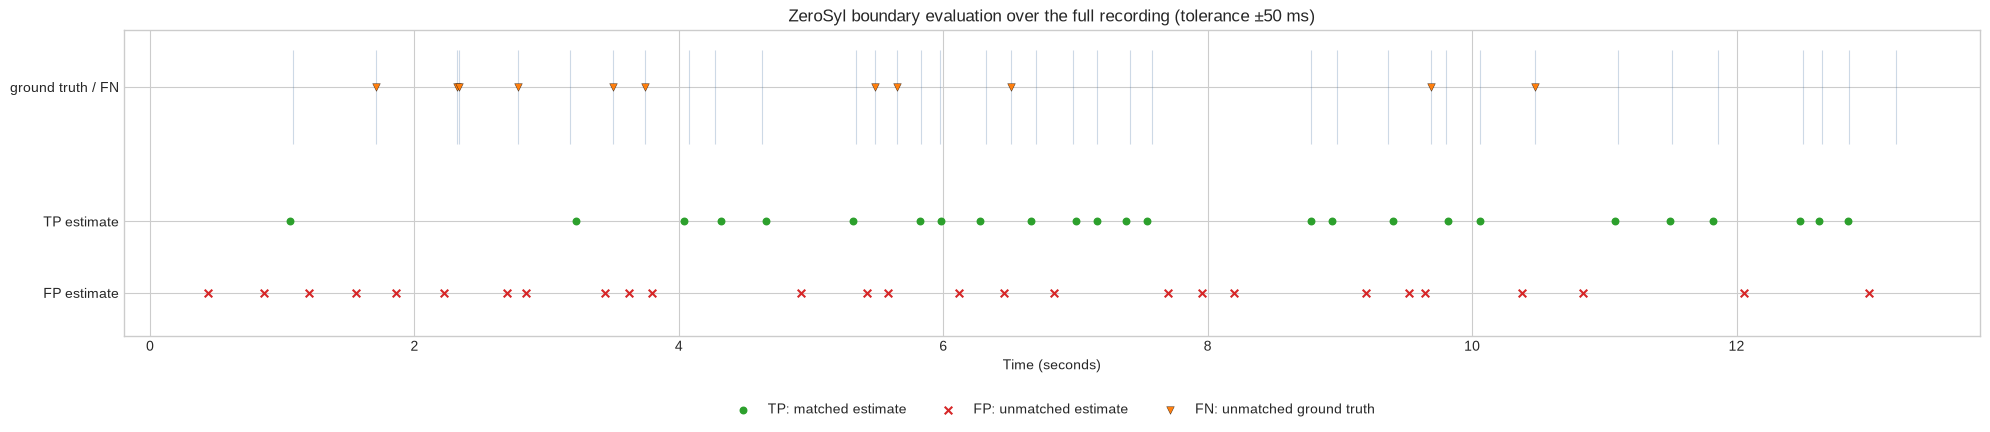

In [10]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")

OUT_PATH = "/home/hendrik/Skripsie/Skripsie Documentation/Images/Qualitative/Hendrik Speech/full_evaluation.png"

plt.style.use("seaborn-v0_8-whitegrid")


def plot_full_evaluation(ground_truth, tp_pairs, fp_times, fn_times, tolerance_s, figsize=(20, 4.5)):
    fig, ax = plt.subplots(figsize=figsize)

    for time in ground_truth:
        ax.vlines(time, 0.72, 1.05, color="#4C78A8", alpha=0.28, linewidth=0.8)

    tp_times = [seg_t for _, seg_t in tp_pairs]
    if tp_times:
        ax.scatter(tp_times, np.full(len(tp_times), 0.45), color="#2CA02C", s=22,
                    marker="o", label="TP: matched estimate", zorder=4)
    if fp_times:
        ax.scatter(fp_times, np.full(len(fp_times), 0.20), color="#D62728", s=30,
                    marker="x", label="FP: unmatched estimate", zorder=5)
    if fn_times:
        ax.scatter(fn_times, np.full(len(fn_times), 0.92), color="#FF7F0E",
                    edgecolor="black", linewidth=0.25, s=30, marker="v",
                    label="FN: unmatched ground truth", zorder=5)

    ax.set_ylim(0.05, 1.12)
    ax.set_yticks([0.20, 0.45, 0.92])
    ax.set_yticklabels(["FP estimate", "TP estimate", "ground truth / FN"])
    ax.set_xlabel("Time (seconds)")
    ax.set_title(f"ZeroSyl boundary evaluation over the full recording (tolerance ±{tolerance_s * 1000:.0f} ms)")
    ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.18))
    plt.tight_layout()
    plt.show()
    
    


plot_full_evaluation(ground_truth_boundaries, tp_pairs, fp_times, fn_times, TOLERANCE_S)

In [11]:
#SAVE YOUR OUTPUT

# import matplotlib.pyplot as plt
# import numpy as np

# plt.style.use("seaborn-v0_8-whitegrid")

# OUT_PATH = "/home/hendrik/Skripsie/Skripsie Documentation/Images/Qualitative/Hendrik Speech/full_evaluation.png"


# def plot_full_evaluation(ground_truth, tp_pairs, fp_times, fn_times, tolerance_s,
#                          figsize=(20, 4.5), save_path=None):
#     fig, ax = plt.subplots(figsize=figsize)

#     for time in ground_truth:
#         ax.vlines(time, 0.72, 1.05, color="#4C78A8", alpha=0.28, linewidth=0.8)

#     tp_times = [seg_t for _, seg_t in tp_pairs]
#     if tp_times:
#         ax.scatter(tp_times, np.full(len(tp_times), 0.45), color="#2CA02C", s=22,
#                    marker="o", label="TP: matched estimate", zorder=4)
#     if fp_times:
#         ax.scatter(fp_times, np.full(len(fp_times), 0.20), color="#D62728", s=30,
#                    marker="x", label="FP: unmatched estimate", zorder=5)
#     if fn_times:
#         ax.scatter(fn_times, np.full(len(fn_times), 0.92), color="#FF7F0E",
#                    edgecolor="black", linewidth=0.25, s=30, marker="v",
#                    label="FN: unmatched ground truth", zorder=5)

#     ax.set_ylim(0.05, 1.12)
#     ax.set_yticks([0.20, 0.45, 0.92])
#     ax.set_yticklabels(["FP estimate", "TP estimate", "ground truth / FN"])
#     ax.set_xlabel("Time (seconds)")
#     ax.set_title(f"ZeroSyl boundary evaluation over the full recording (tolerance ±{tolerance_s * 1000:.0f} ms)")
#     ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.18))
#     plt.tight_layout()

#     if save_path:
#         fig.savefig(save_path, dpi=300, bbox_inches="tight")
#         print(f"Saved to {save_path}")

#     return fig


# plot_full_evaluation(ground_truth_boundaries, tp_pairs, fp_times, fn_times,
#                      TOLERANCE_S, save_path=OUT_PATH)

## 7. Tool 2 — Synchronized scrollable viewer (ground truth vs. estimate vs. audio)

A new tool, not in the old notebook. One large, scrollable view stacking four
synchronized panels over the same time axis, so the boundary performance,
both `TextGrid` tiers, and the waveform can all be compared at a glance:

1. **Boundary evaluation** — TP (green), FP (red), FN (orange), each with its
   ±tolerance window shaded. A green connecting line links every matched
   pair. The unshaded background is labelled **TN** — there is no boundary
   event predicted or expected there, which is the only sense in which "true
   negative" applies to a sparse boundary-detection task.
2. **Ground-truth tier** — Praat-style interval boxes with their labels.
3. **Estimated tier** — same style, for the ZeroSyl output.
4. **Waveform** — the audio underlying the current window.

Drag the **start** slider to scroll through the recording and the **window**
slider to zoom in/out; an audio player for the currently visible window is
shown underneath so you can listen to exactly what's on screen.

In [10]:
import soundfile as sf
from IPython.display import Audio, display

audio_data, sample_rate = sf.read(AUDIO_WAV)
if audio_data.ndim > 1:
    audio_data = audio_data.mean(axis=1)
recording_duration = len(audio_data) / sample_rate

tp_ref_times = [ref_t for ref_t, _ in tp_pairs]
tp_seg_times = [seg_t for _, seg_t in tp_pairs]


def _draw_tier(ax, tier, start_s, end_s, color):
    window_s = end_s - start_s
    for iv in tier.intervals:
        if iv.end_time <= start_s or iv.start_time >= end_s:
            continue
        left = max(iv.start_time, start_s)
        right = min(iv.end_time, end_s)
        ax.axvspan(left, right, color=color, alpha=0.15, linewidth=0)
        ax.axvline(iv.start_time, color=color, linewidth=1.0, alpha=0.6)
        interval_width = right - left
        if iv.text.strip():
            # Adapt label size/rotation to how much horizontal room the interval
            # has in the current window, so short syllables don't overlap.
            if interval_width < window_s * 0.012:
                pass  # too narrow for any legible label
            elif interval_width < window_s * 0.035:
                ax.text((left + right) / 2, 0.5, iv.text, ha="center", va="center",
                         fontsize=7, color="black", rotation=90)
            else:
                ax.text((left + right) / 2, 0.5, iv.text, ha="center", va="center",
                         fontsize=9, color="black")
    ax.axvline(end_s, color=color, linewidth=1.0, alpha=0.0)  # keep xlim consistent
    ax.set_xlim(start_s, end_s)
    ax.set_ylim(0, 1)
    ax.set_yticks([])

_LAST_FIG = {"fig": None}
def render_window(start_s: float, window_s: float, play_audio: bool = True):
    start_s = max(0.0, min(start_s, recording_duration - 0.01))
    end_s = min(recording_duration, start_s + window_s)

    fig, axes = plt.subplots(
        4, 1, figsize=(18, 10), sharex=True, layout="constrained",
        gridspec_kw={"height_ratios": [2.0, 1.0, 1.0, 1.6], "hspace": 0.12},
    )
    ax_perf, ax_gt, ax_est, ax_wave = axes
    _LAST_FIG["fig"] = fig

    for ax in axes:
        ax.grid(False)

    # --- Panel 1: boundary evaluation zoom ---
    ax_perf.axvspan(start_s, end_s, color="#DDDDDD", alpha=0.35, zorder=0)  # TN background

    visible_gt = [t for t in ground_truth_boundaries if start_s <= t <= end_s]
    for t in visible_gt:
        ax_perf.axvspan(t - TOLERANCE_S, t + TOLERANCE_S, color="#4C78A8", alpha=0.15, linewidth=0, zorder=1)
        ax_perf.vlines(t, 0.65, 1.08, color="#4C78A8", linewidth=1.2, zorder=2)

    for ref_t, seg_t in tp_pairs:
        if start_s - TOLERANCE_S <= ref_t <= end_s + TOLERANCE_S or start_s - TOLERANCE_S <= seg_t <= end_s + TOLERANCE_S:
            ax_perf.plot([ref_t, seg_t], [0.82, 0.35], color="#2CA02C", alpha=0.7, linewidth=1.2, zorder=3)

    visible_tp = [t for t in tp_seg_times if start_s <= t <= end_s]
    visible_fp = [t for t in fp_times if start_s <= t <= end_s]
    visible_fn = [t for t in fn_times if start_s <= t <= end_s]

    if visible_tp:
        ax_perf.scatter(visible_tp, np.full(len(visible_tp), 0.35), color="#2CA02C", s=70, marker="o", zorder=5, label="TP")
    if visible_fp:
        ax_perf.scatter(visible_fp, np.full(len(visible_fp), 0.15), color="#D62728", s=90, marker="x", linewidths=2.5, zorder=5, label="FP")
    if visible_fn:
        ax_perf.scatter(visible_fn, np.full(len(visible_fn), 0.82), color="#FF7F0E", edgecolor="black", linewidth=0.4, s=90, marker="v", zorder=5, label="FN")

    ax_perf.set_ylim(0.0, 1.15)
    ax_perf.set_yticks([0.15, 0.35, 0.82])
    ax_perf.set_yticklabels(["FP", "TP", "GT / FN"])
    ax_perf.set_xlim(start_s, end_s)
    ax_perf.set_title(
        f"Boundary evaluation  —  window {start_s:.2f}s\u2013{end_s:.2f}s  "
        f"(TP={len(visible_tp)}, FP={len(visible_fp)}, FN={len(visible_fn)}, tolerance \u00b1{TOLERANCE_S*1000:.0f} ms)",
        fontsize=11, loc="left",
    )
    handles, labels = ax_perf.get_legend_handles_labels()
    if handles:
        ax_perf.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.02),
                        ncol=len(handles) + 1, fontsize=9, frameon=False)
        ax_perf.text(1.0, 1.02, "grey = TN (no boundary predicted or expected)",
                      transform=ax_perf.transAxes, ha="right", va="bottom", fontsize=8, style="italic")

    # --- Panels 2 & 3: TextGrid tiers ---
    _draw_tier(ax_gt, gt_tier, start_s, end_s, "#4C78A8")
    ax_gt.set_ylabel("Ground truth", rotation=0, ha="right", va="center", fontsize=10)

    _draw_tier(ax_est, est_tier, start_s, end_s, "#2CA02C")
    ax_est.set_ylabel("Estimate", rotation=0, ha="right", va="center", fontsize=10)

    # --- Panel 4: waveform ---
    sample_start = int(start_s * sample_rate)
    sample_end = int(end_s * sample_rate)
    times = np.linspace(start_s, end_s, sample_end - sample_start, endpoint=False)
    ax_wave.plot(times, audio_data[sample_start:sample_end], color="#333333", linewidth=0.5)
    ax_wave.set_xlim(start_s, end_s)
    ax_wave.set_xlabel("Time (seconds)")
    ax_wave.set_ylabel("Waveform")

    plt.show()

    if play_audio:
        print(f"Audio for the visible window ({start_s:.2f}s\u2013{end_s:.2f}s):")
        display(Audio(audio_data[sample_start:sample_end], rate=sample_rate))

Run the cell below. If `ipywidgets` is available you get a slider you can
drag to scroll through the whole recording; otherwise call
`render_window(start_s, window_s)` directly with the values you want.

In [11]:
try:
    import ipywidgets as widgets

    widgets.interact(
        render_window,
        start_s=widgets.FloatSlider(
            min=0.0, max=max(0.0, recording_duration - 1.0), step=0.5, value=0.0,
            description="start (s)", continuous_update=False, layout=widgets.Layout(width="700px"),
        ),
        window_s=widgets.FloatSlider(
            min=1.0, max=20.0, step=0.5, value=6.0,
            description="window (s)", continuous_update=False, layout=widgets.Layout(width="700px"),
        ),
        play_audio=widgets.Checkbox(value=True, description="play audio"),
    )
except ImportError:
    print("ipywidgets is not installed — install it (`pip install ipywidgets`) for the slider, "
          "or call render_window(start_s, window_s) directly, e.g.:")
    render_window(start_s=0.0, window_s=6.0)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='start (s)', layout=Layout(w…

In [12]:
# After moving the slider to the view you want, run this cell to save it:



# OUT_PATH = "/home/hendrik/Skripsie/Skripsie Documentation/Images/Qualitative/Hendrik Speech/window_view1.png"
OUT_PATH = "/home/hendrik/Skripsie/Skripsie Documentation/Images/Qualitative/Babaloon/losHyDieBabaloon.png"
fig = _LAST_FIG["fig"]
if fig is None:
    print("No figure rendered yet — move the slider (or call render_window) first.")
else:
    fig.savefig(OUT_PATH, dpi=300, bbox_inches="tight")
    print(f"Saved to {OUT_PATH}")

Saved to /home/hendrik/Skripsie/Skripsie Documentation/Images/Qualitative/Babaloon/losHyDieBabaloon.png
